# **TAREA GRUPAL 3**
---

Diego Eduardo Monja Zagaceta — 20242642

Alessandra Isabel Mendoza Tordoya — 20245523

Jorge Daniel Quiroz Huamán — 20267609


---

Unidad territorial: comunas de Chile |
Variable: hogares carentes de servicios básicos en el RSH (%) — 2025


---



## 1. Instalación e importación de librerías
Se reúnen las librerías para leer información geográfica, integrar tablas y desarrollar posteriormente el análisis de vecindad y autocorrelación espacial.

In [ ]:
# Instalar las librerías necesarias
!pip -q install geopandas libpysal esda mapclassify thefuzz

In [ ]:
# Importación de librerías para el análisis espacial
import geopandas as gpd
import pandas as pd
import esda
import matplotlib.pyplot as plt
# Importación de herramientas para las coincidencias
from thefuzz.process import extractOne as best
# Importación de herramientas para construir grafos de vecindad
from libpysal.graph import Graph
# Configuración de la semilla para garantizar la reproducibilidad
from numpy.random import seed
seed(42)

## 2. Carga de datos geográficos y estadísticos
Se lee la capa de comunas y se inspecciona su estructura, sistema de coordenadas y tipo de proyección, siguiendo la secuencia de revisión de la cartografía original. Además, se carga la tabla del indicador social.

In [ ]:
# Enlaces de los archivos publicados en GitHub
chileDataLink = "https://github.com/Alessandra-mt/Tarea-Grupal-3/raw/main/comunas%20chile.zip"
bcnDataLink = "https://github.com/Alessandra-mt/Tarea-Grupal-3/raw/main/Comunas_Chile_datos.csv"
# Carga de la capa original
comunas = gpd.read_file(chileDataLink)
# Inspección del CRS y sus características
comunas.info(),comunas.crs.to_epsg(),comunas.crs.is_projected


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 345 entries, 0 to 344
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   GID_3      345 non-null    object  
 1   GID_0      345 non-null    object  
 2   COUNTRY    345 non-null    object  
 3   GID_1      345 non-null    object  
 4   NAME_1     345 non-null    object  
 5   NL_NAME_1  345 non-null    object  
 6   GID_2      345 non-null    object  
 7   NAME_2     345 non-null    object  
 8   NL_NAME_2  345 non-null    object  
 9   NAME_3     345 non-null    object  
 10  VARNAME_3  345 non-null    object  
 11  NL_NAME_3  345 non-null    object  
 12  TYPE_3     345 non-null    object  
 13  ENGTYPE_3  345 non-null    object  
 14  CC_3       345 non-null    object  
 15  HASC_3     345 non-null    object  
 16  geometry   345 non-null    geometry
dtypes: geometry(1), object(16)
memory usage: 45.9+ KB


(None, 4326, False)

In [ ]:
# Carga de la información estadística
datos = pd.read_csv(bcnDataLink)
# Revisión de los datos
datos.info()
datos.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 345 entries, 0 to 344
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unidad territorial  345 non-null    object 
 1    Variable           345 non-null    object 
 2    2025               345 non-null    float64
dtypes: float64(1), object(2)
memory usage: 8.2+ KB


,Unidad territorial,Variable,2025
0,General Lagos (Región de Arica y Parinacota),Hogares carentes de servicios básicos el RSH (%),96.959459
1,Putre (Región de Arica y Parinacota),Hogares carentes de servicios básicos el RSH (%),58.823529
2,Arica (Región de Arica y Parinacota),Hogares carentes de servicios básicos el RSH (%),11.282294
3,Camarones (Región de Arica y Parinacota),Hogares carentes de servicios básicos el RSH (%),74.568966
4,Colchane,Hogares carentes de servicios básicos el RSH (%),87.122970


In [ ]:
# Identificación de los nombres de las columnas
comunas.columns,datos.columns

(Index(['GID_3', 'GID_0', 'COUNTRY', 'GID_1', 'NAME_1', 'NL_NAME_1', 'GID_2',
        'NAME_2', 'NL_NAME_2', 'NAME_3', 'VARNAME_3', 'NL_NAME_3', 'TYPE_3',
        'ENGTYPE_3', 'CC_3', 'HASC_3', 'geometry'],
       dtype='object'),
 Index(['Unidad territorial', ' Variable', ' 2025'], dtype='object'))

## 3. Revisión de identificadores
Se comprueba la existencia de identificadores repetidos en la cartografía.

In [ ]:
# Mostrar todos los nombres de comunas duplicados
comunas[comunas["NAME_3"].duplicated(keep=False)].sort_values("NAME_3")

,GID_3,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,GID_2,NAME_2,NL_NAME_2,NAME_3,VARNAME_3,NL_NAME_3,TYPE_3,ENGTYPE_3,CC_3,HASC_3,geometry
8,CHL.2.3.2_1,CHL,Chile,CHL.2_1,Antofagasta,NA,CHL.2.3_1,Tocopilla,NA,Tocopilla,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-70.2891 -22.5714, -70.2893 -2..."
306,CHL.15.1.7_1,CHL,Chile,CHL.15_1,Tarapacá,NA,CHL.15.1_1,Tamarugal,NA,Tocopilla,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-69.5514 -21.6301, -69.5539 -2..."


In [ ]:
# Códigos geográficos repetidos
comunas[comunas["GID_3"].duplicated()]

,GID_3,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,GID_2,NAME_2,NL_NAME_2,NAME_3,VARNAME_3,NL_NAME_3,TYPE_3,ENGTYPE_3,CC_3,HASC_3,geometry


Hay un error en los datos cartográficos, pues no existen una comuna llamada Tocopilla en Tarapacá. Tacopilla pertenece a la región de Antofagasta, mientras que Pozo Almonte pertece a la región de Tarapacá

In [ ]:
# Corrección del registro de Pozo Almonte en la cartografía de Tarapacá
comunas.loc[comunas['GID_3']=='CHL.15.1.7_1','NAME_3']='PozoAlmonte'

## 4. Homogeneización de nombres e integración de datos
Se aplica la secuencia de la evaluación grupal anterior: renombrado de la clave, comparación de nombres, revisión de diferencias y unión mediante **merge**. Antes de ejecutar el renombrado de la tabla, debe sustituirse el nombre de la columna comunal por el que aparezca en **datos.columns**. No se presupone su nombre.

In [ ]:
# Homonizamos el nombre de las columnas
datos.columns=datos.columns.str.strip()
datos.rename(columns={'Unidad territorial':'Comuna'},inplace=True)
comunas.rename(columns={'NAME_3':'Comuna'},inplace=True)
# Se separa el nombre comunal del texto regional entre paréntesis
datos['Comuna']=datos['Comuna'].str.split(' (',regex=False).str[0]

In [ ]:
# Verificamos qué comunas no son reconocidas entre las fuentes
onlyDF = set(datos.Comuna) - set(comunas.Comuna)
onlyGDF = set(comunas.Comuna) - set(datos.Comuna)
print('Solo en datos:', onlyDF)
print('Solo en cartografía:', onlyGDF)

Solo en datos: {'El Tabo', 'Nueva Imperial', 'La Unión', 'Sierra Gorda', 'El Carmen', 'El Bosque', 'San Ramón', 'San Antonio', 'Lago Ranco', 'San Miguel', 'Los Vilos', 'San José De Maipo', 'Río Bueno', 'Diego De Almagro', 'Lo Espejo', 'Santo Domingo', 'La Reina', 'Pozo Almonte', 'La Ligua', 'Los Andes', 'San Juan De La Costa', 'Quinta Normal', 'María Pinto', 'Estación Central', 'Curaco De Vélez', 'Punta Arenas', 'La Florida', 'Las Condes', 'San Fernando', 'Alto Hospicio', 'Santa Bárbara', 'San Carlos', 'La Estrella', 'Puerto Varas', 'Torres Del Paine', 'Río Hurtado', 'María Elena', 'Monte Patria', 'Marchihue', 'Chile Chico', 'Lago Verde', 'Los Álamos', 'O’higgins', 'Padre Hurtado', 'Los Ángeles', 'San Pedro De La Paz', 'Chillán Viejo', 'San Ignacio', 'La Serena', 'Río Ibáñez', 'Las Cabras', 'Cerro Navia', 'Río Claro', 'Alto Biobío', 'Cabo De Hornos', 'La Cisterna', 'Lo Barnechea', 'San Rosendo', 'Laguna Blanca', 'San Pedro De Atacama', 'Los Sauces', 'Quinta De Tilcoco', 'San Bernardo',

In [ ]:
#Se muestran las coincidencias y su nivel de similitud
pd.DataFrame([(Comuna, best(Comuna,onlyGDF)[0],best(Comuna,onlyGDF)[1]) for Comuna in onlyDF]).sort_values(by=2)

,0,1,2
38,Marchihue,Marchigüe,82
45,San Pedro De La Paz,SanPedrodelaPaz,88
108,Paiguano,Paihuano,88
20,San Juan De La Costa,SanJuandelaCosta,89
41,Los Álamos,LosAlamos,89
...,...,...,...
91,Sagrada Familia,SagradaFamilia,97
23,Estación Central,EstaciónCentral,97
63,Tierra Amarilla,TierraAmarilla,97
78,Teodoro Schmidt,TeodoroSchmidt,97


In [ ]:
#Creamos el diccionario con las regiones
changesToDF = {Comuna:best(Comuna,onlyGDF)[0] for Comuna in onlyDF}
changesToDF

{'El Tabo': 'ElTabo',
 'Nueva Imperial': 'NuevaImperial',
 'La Unión': 'LaUnión',
 'Sierra Gorda': 'SierraGorda',
 'El Carmen': 'ElCarmen',
 'El Bosque': 'ElBosque',
 'San Ramón': 'SanRamón',
 'San Antonio': 'SanAntonio',
 'Lago Ranco': 'LagoRanco',
 'San Miguel': 'SanMiguel',
 'Los Vilos': 'LosVilos',
 'San José De Maipo': 'SanJosédeMaipo',
 'Río Bueno': 'RíoBueno',
 'Diego De Almagro': 'DiegodeAlmagro',
 'Lo Espejo': 'LoEspejo',
 'Santo Domingo': 'SantoDomingo',
 'La Reina': 'LaReina',
 'Pozo Almonte': 'PozoAlmonte',
 'La Ligua': 'LaLigua',
 'Los Andes': 'LosAndes',
 'San Juan De La Costa': 'SanJuandelaCosta',
 'Quinta Normal': 'QuintaNormal',
 'María Pinto': 'MaríaPinto',
 'Estación Central': 'EstaciónCentral',
 'Curaco De Vélez': 'CuracodeVélez',
 'Punta Arenas': 'PuntaArenas',
 'La Florida': 'LaFlorida',
 'Las Condes': 'LasCondes',
 'San Fernando': 'SanFernando',
 'Alto Hospicio': 'AltoHospicio',
 'Santa Bárbara': 'SantaBárbara',
 'San Carlos': 'SanCarlos',
 'La Estrella': 'LaEstr

In [ ]:
# Al ver que las coincidencias son correctas realizamos el reemplazo
datos.replace(to_replace={'Comuna':changesToDF},inplace=True)

In [ ]:
# Verificamos si aún quedan comunas sin correspondencia
onlyDF = set(datos.Comuna) - set(comunas.Comuna)
onlyGDF = set(comunas.Comuna) - set(datos.Comuna)
print('Solo en datos:', len(onlyDF))
print('Solo en cartografía:', len(onlyGDF))

Solo en datos: 0
Solo en cartografía: 0


In [ ]:
# Se une la información espacial con los datos estadísticos
MapaDatosChile=comunas.merge(datos,on='Comuna')
# Cambiamos el nombre de la columna que contiene los datos por una más detallada
MapaDatosChile=MapaDatosChile.rename(
    columns={'2025': 'Hogares_Carentes_de_Servicios_Basicos'}
)
MapaDatosChile

,GID_3,GID_0,COUNTRY,GID_1,NAME_1,NL_NAME_1,GID_2,NAME_2,NL_NAME_2,Comuna,VARNAME_3,NL_NAME_3,TYPE_3,ENGTYPE_3,CC_3,HASC_3,geometry,Variable,Hogares_Carentes_de_Servicios_Basicos
0,CHL.2.1.1_1,CHL,Chile,CHL.2_1,Antofagasta,NA,CHL.2.1_1,Antofagasta,NA,Antofagasta,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-68.4842 -25.158, -68.4876 -25...",Hogares carentes de servicios básicos el RSH (%),8.902864
1,CHL.2.1.2_1,CHL,Chile,CHL.2_1,Antofagasta,NA,CHL.2.1_1,Antofagasta,NA,Mejillones,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-70.0138 -23.0579, -70.0148 -2...",Hogares carentes de servicios básicos el RSH (%),17.782501
2,CHL.2.1.3_1,CHL,Chile,CHL.2_1,Antofagasta,NA,CHL.2.1_1,Antofagasta,NA,SierraGorda,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-68.6986 -23.9231, -68.874 -23...",Hogares carentes de servicios básicos el RSH (%),24.368231
3,CHL.2.1.4_1,CHL,Chile,CHL.2_1,Antofagasta,NA,CHL.2.1_1,Antofagasta,NA,Taltal,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-70.7009 -25.8919, -70.6999 -2...",Hogares carentes de servicios básicos el RSH (%),25.101703
4,CHL.2.2.1_1,CHL,Chile,CHL.2_1,Antofagasta,NA,CHL.2.2_1,ElLoa,NA,Calama,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-68.0419 -22.0036, -68.0148 -2...",Hogares carentes de servicios básicos el RSH (%),17.728742
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
340,CHL.16.7.3_1,CHL,Chile,CHL.16_1,Valparaíso,NA,CHL.16.7_1,Valparaíso,NA,JuanFernández,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-80.7833 -33.7225, -80.7727 -3...",Hogares carentes de servicios básicos el RSH (%),35.726795
341,CHL.16.7.4_1,CHL,Chile,CHL.16_1,Valparaíso,NA,CHL.16.7_1,Valparaíso,NA,Puchuncaví,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-71.4293 -32.6323, -71.4244 -3...",Hogares carentes de servicios básicos el RSH (%),35.743882
342,CHL.16.7.5_1,CHL,Chile,CHL.16_1,Valparaíso,NA,CHL.16.7_1,Valparaíso,NA,Quintero,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-71.5195 -32.8892, -71.521 -32...",Hogares carentes de servicios básicos el RSH (%),23.526368
343,CHL.16.7.6_1,CHL,Chile,CHL.16_1,Valparaíso,NA,CHL.16.7_1,Valparaíso,NA,Valparaíso,NA,NA,Comuna,Municipality,NA,NA,"MULTIPOLYGON (((-71.4925 -33.1044, -71.479 -33...",Hogares carentes de servicios básicos el RSH (%),11.876980


## 5. Reproyección y preparación de la capa integrada
Se reproyecta la capa integrada a EPSG:5361, como en el trabajo de integración de Chile, y se guarda en GeoPackage para continuar con los análisis espaciales.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

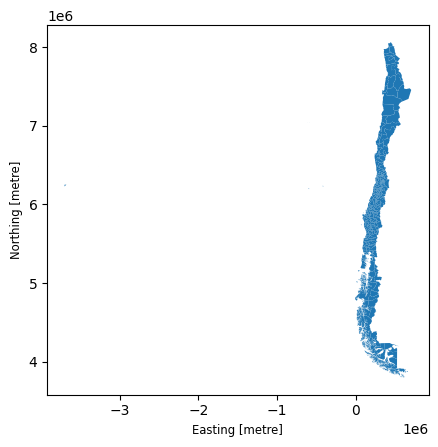

In [ ]:
# Transformamos el mapa al sistema de coordenadas 5361
MapaDatosChile_5361=MapaDatosChile.to_crs(5361)
# Se comprueba visualmente la proyección
MapaDatosChile_5361.plot()

In [ ]:
# Revisión de la capa integrada
MapaDatosChile_5361.info()
MapaDatosChile_5361['Hogares_Carentes_de_Servicios_Basicos'].describe()
len(MapaDatosChile_5361)

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 345 entries, 0 to 344
Data columns (total 19 columns):
 #   Column                                 Non-Null Count  Dtype   
---  ------                                 --------------  -----   
 0   GID_3                                  345 non-null    object  
 1   GID_0                                  345 non-null    object  
 2   COUNTRY                                345 non-null    object  
 3   GID_1                                  345 non-null    object  
 4   NAME_1                                 345 non-null    object  
 5   NL_NAME_1                              345 non-null    object  
 6   GID_2                                  345 non-null    object  
 7   NAME_2                                 345 non-null    object  
 8   NL_NAME_2                              345 non-null    object  
 9   Comuna                                 345 non-null    object  
 10  VARNAME_3                              345 non-null   

345

## 6. Exploración de la variable social
Se obtienen las estadísticas descriptivas del porcentaje de hogares carentes de servicios básicos en 2025 y se representa su distribución mediante un mapa coroplético clasificado por cuantiles. Este mapa permite observar la variable antes del análisis de autocorrelación espacial; no constituye un mapa LISA.

In [ ]:
# Estadísticas descriptivas
MapaDatosChile_5361['Hogares_Carentes_de_Servicios_Basicos'].describe()

,Hogares_Carentes_de_Servicios_Basicos
count,345.000000
mean,22.776570
std,15.015432
min,2.221074
25%,11.903162
50%,19.008264
75%,31.023334
max,96.959459


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

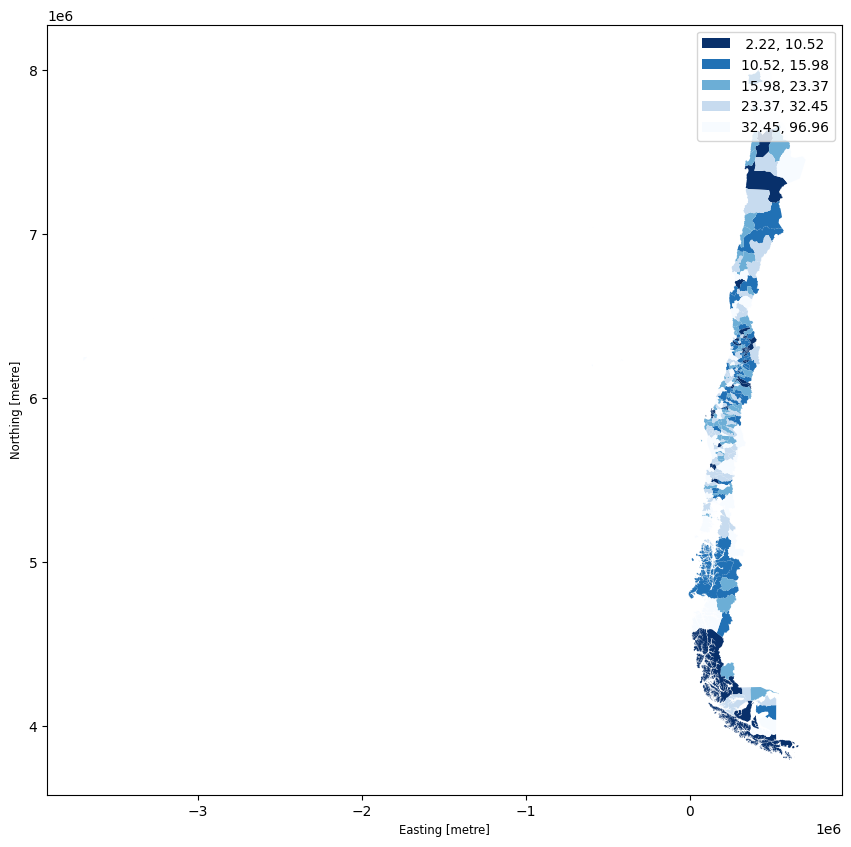

In [ ]:
# Mapa descriptivo de la variable social
MapaDatosChile_5361.plot('Hogares_Carentes_de_Servicios_Basicos',scheme='quantiles',cmap='Blues_r',legend=True,figsize=(12,10))

# 7. Creación del vecindario

Se creará el vecindario KNN con K=3, pues cada distrito tendrá como vecinos a sus tres distritos más cercanos, según la ubicación de sus puntos representativos.

In [ ]:
# Construcción del vecindario KNN con k=3
knn = Graph.build_knn(MapaDatosChile_5361.representative_point(), k=3)

# Identificar distritos aislados
print("Distritos aislados:", len(knn.isolates))

Distritos aislados: 0


Text(0.5, 1.0, 'Vecindario KNN con K=3')

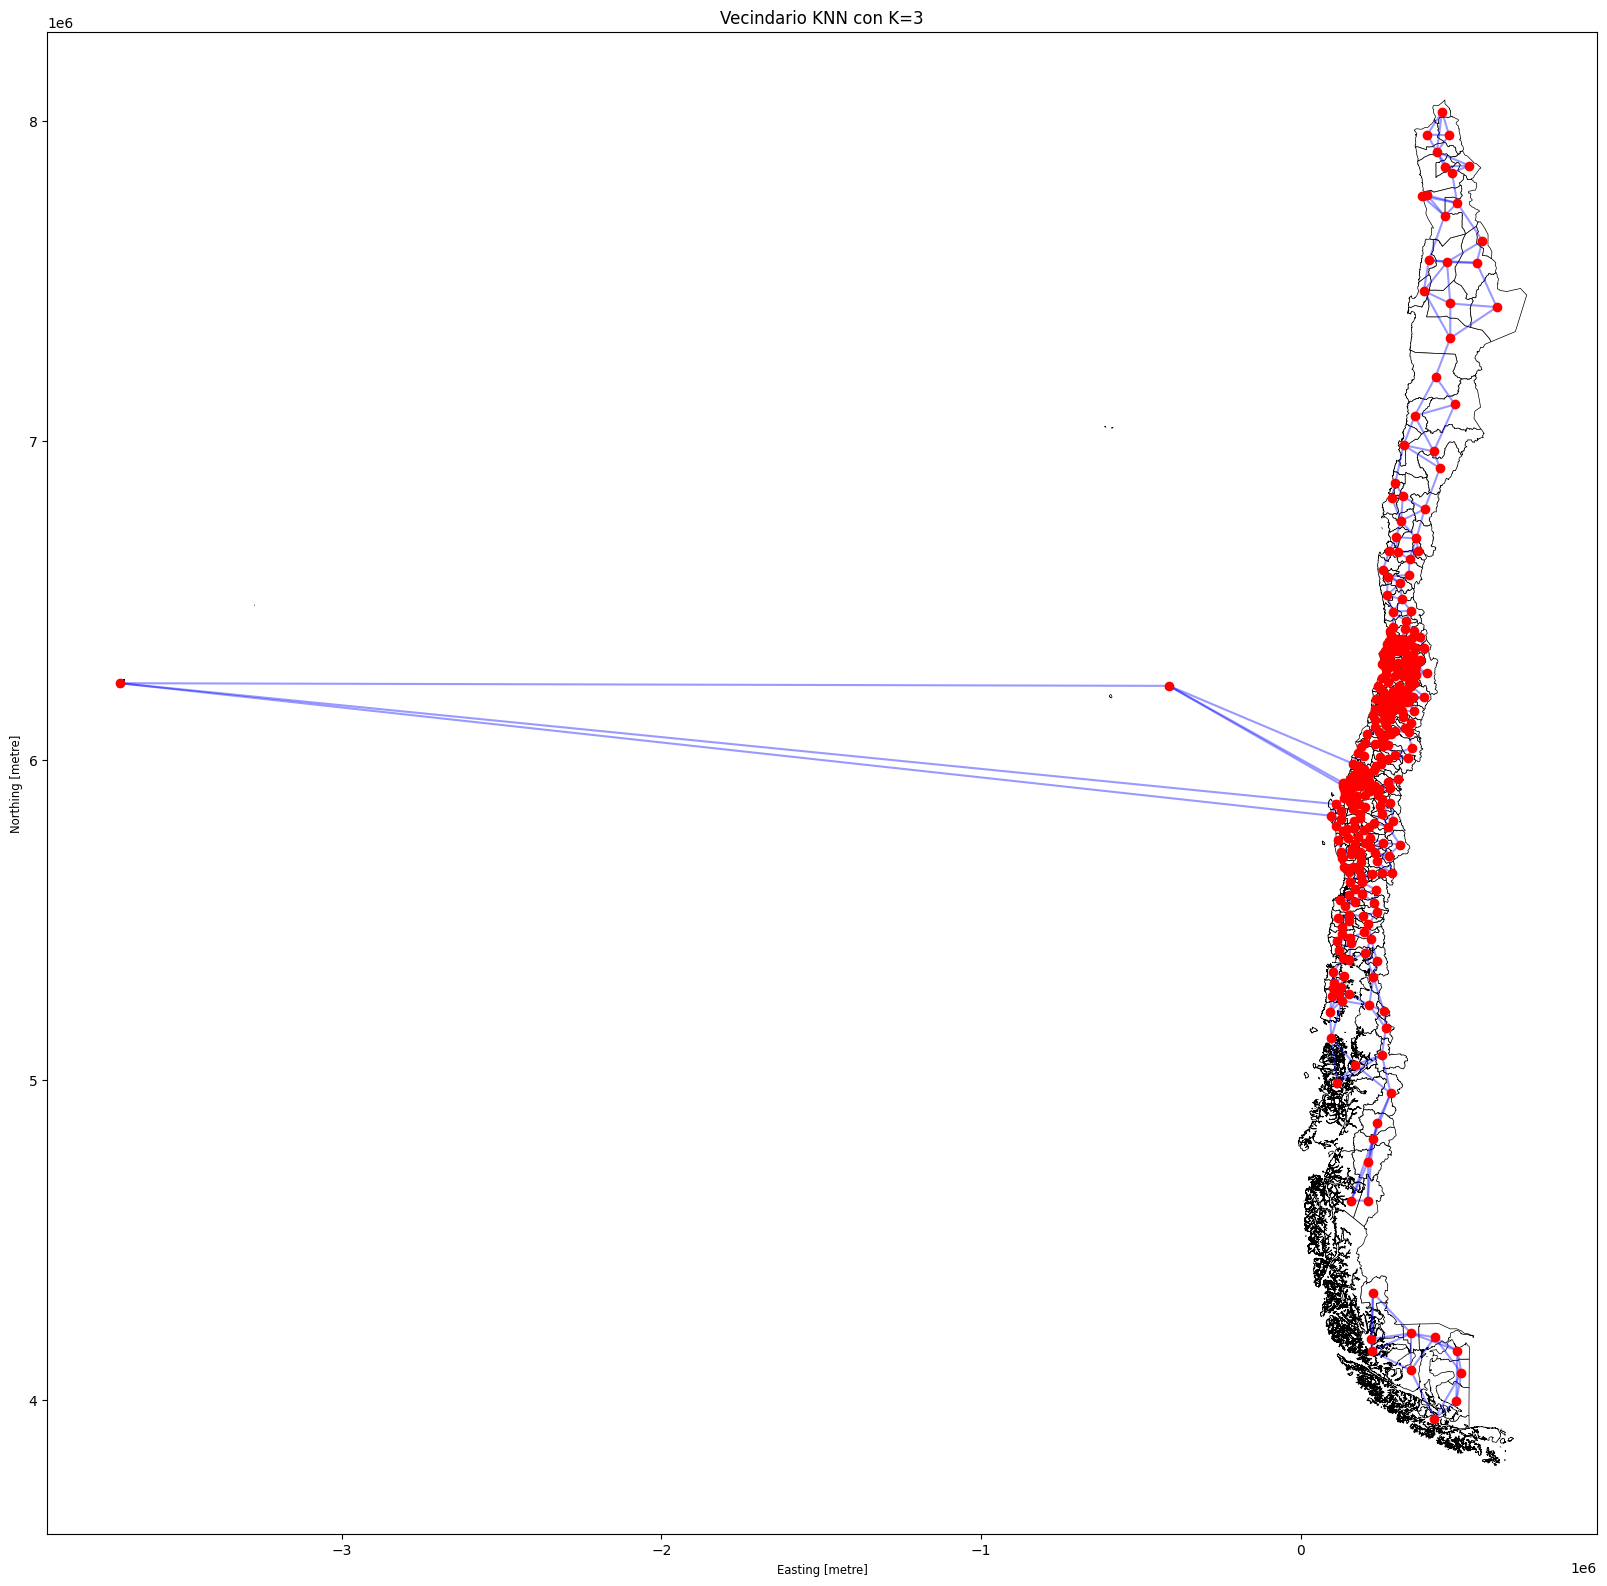

In [ ]:
# Como no hay distritos aislados, continuamos

# Visualización del vecindario
base = MapaDatosChile_5361.plot(figsize=(20,20), facecolor="white", edgecolor="black", linewidth=0.5)
knn.plot(ax=base, gdf=MapaDatosChile_5361, node_kws=dict(color="red"),edge_kws=dict(alpha=0.4, color="blue"))
plt.title("Vecindario KNN con K=3")

# 8. Creamos LISA para las comunas

Los pesos espaciales obtenidos fueron estandarizados por filas para realizar el análisis de autocorrelación espacial local (LISA).

In [ ]:
# Estandarización de pesos
knn = knn.transform("r")

# Cálculo de Moran Local
lisa_knn = esda.Moran_Local(MapaDatosChile_5361["Hogares_Carentes_de_Servicios_Basicos"], knn, seed=42)

In [ ]:
labels = {
    "Insignificant": "3 no_pattern",
    "Low-Low": "4 coldSpot",
    "High-High": "2 hotSpot",
    "High-Low": "1 hotOutlier",
    "Low-High": "5 coldOutlier"
}

In [ ]:
#Clasificación de resultados
chile_knn = MapaDatosChile.copy()
chile_knn["LISA"] = lisa_knn.get_cluster_labels(crit_value=0.05)
chile_knn.replace({"LISA":labels}, inplace=True)

chile_knn["LISA"].value_counts().sort_index()

,count
LISA,
1 hotOutlier,2
2 hotSpot,21
3 no_pattern,252
4 coldSpot,63
5 coldOutlier,7


# 9. Resultados del LISA sobre la capa proyectada
Para presentar los resultados, copio la capa proyectada (EPSG:5361) y guardo en ella la categoría LISA de cada comuna, su pseudo p-valor y su rezago espacial, que es el promedio del indicador en sus tres vecinos más cercanos. El orden de las filas es el mismo que el del vecindario, por lo que cada resultado corresponde a su comuna.

In [ ]:
# Copio la capa proyectada para no modificar las variables del grupo
var = "Hogares_Carentes_de_Servicios_Basicos"
chile_lisa = MapaDatosChile_5361.copy()

# Categoría LISA con alfa = 0.05, renombrada con las etiquetas del profesor
chile_lisa["LISA"] = lisa_knn.get_cluster_labels(crit_value=0.05)
chile_lisa["LISA"] = chile_lisa["LISA"].map(labels)

chile_lisa["p_sim"] = lisa_knn.p_sim                # pseudo p-valor de cada comuna
chile_lisa["Rezago"] = knn.lag(chile_lisa[var])     # promedio de sus 3 vecinos

chile_lisa["LISA"].value_counts().sort_index()

,count
LISA,
1 hotOutlier,2
2 hotSpot,21
3 no_pattern,252
4 coldSpot,63
5 coldOutlier,7


# 10. Moran Global
Antes de interpretar los resultados locales, calculo el índice de Moran Global con el mismo vecindario KNN (k = 3) normalizado por filas. Este índice indica si, en conjunto, las comunas con porcentajes parecidos de hogares carentes de servicios básicos tienden a estar cerca unas de otras. Uso 999 permutaciones y la misma semilla del análisis.

In [ ]:
seed(42)                                            # misma semilla del análisis
moran = esda.Moran(chile_lisa[var], knn, permutations=999)
print("I de Moran:", round(moran.I, 4))
print("Pseudo p-valor:", moran.p_sim)

I de Moran: 0.4225
Pseudo p-valor: 0.001


# 11. Revisión de comunas con vecinos lejanos
Con KNN, cada comuna siempre tiene tres vecinos, aunque estén muy lejos. Esto puede ocurrir con las comunas insulares (como Isla de Pascua y Juan Fernández) y con comunas muy extensas del extremo sur. Para evaluarlo, calculo la distancia promedio de cada comuna a sus tres vecinos y reviso las diez con mayor distancia y su categoría LISA.

In [ ]:
import numpy as np
from scipy.spatial import cKDTree

# Puntos representativos en metros (capa proyectada)
pts = MapaDatosChile_5361.representative_point()
xy = np.column_stack([pts.x, pts.y])

# Distancia a los 3 vecinos más cercanos (la columna 0 es la propia comuna)
d, _ = cKDTree(xy).query(xy, k=4)
lejos = pd.Series(d[:, 1:].mean(axis=1) / 1000, index=chile_lisa["Comuna"].values)

top = lejos.sort_values(ascending=False).head(10)
pd.DataFrame({"km_promedio_a_sus_3_vecinos": top.round(0),
              "LISA": chile_lisa.set_index("Comuna").loc[top.index, "LISA"]})

,km_promedio_a_sus_3_vecinos,LISA
IsladePascua,3639.0,3 no_pattern
JuanFernández,625.0,3 no_pattern
TorresdelPaine,167.0,3 no_pattern
SanPedrodeAtacama,158.0,3 no_pattern
CabodeHornos,141.0,3 no_pattern
Antofagasta,136.0,3 no_pattern
DiegodeAlmagro,133.0,3 no_pattern
Aysén,129.0,3 no_pattern
Tortel,129.0,3 no_pattern
PuntaArenas,126.0,3 no_pattern


# 12. Mapa LISA
Presento el mapa LISA de las comunas de Chile con las cinco categorías: hotSpot (alto rodeado de altos), coldSpot (bajo rodeado de bajos), hotOutlier (alto rodeado de bajos), coldOutlier (bajo rodeado de altos) y comunas sin patrón significativo. Como la variable mide carencia, **un valor alto significa más hogares sin servicios básicos**: un hotSpot es una agrupación de comunas con alta carencia y un coldSpot, una agrupación con baja carencia. Uso la paleta divergente del profesor y el mismo nivel de significancia de 0.05. Se muestran todas las comunas del territorio continental, incluidas las no significativas. Isla de Pascua y Juan Fernández no se dibujan porque estiran el mapa miles de kilómetros; ambas resultaron sin patrón significativo.

            Comuna          LISA
307   IsladePascua  3 no_pattern
340  JuanFernández  3 no_pattern


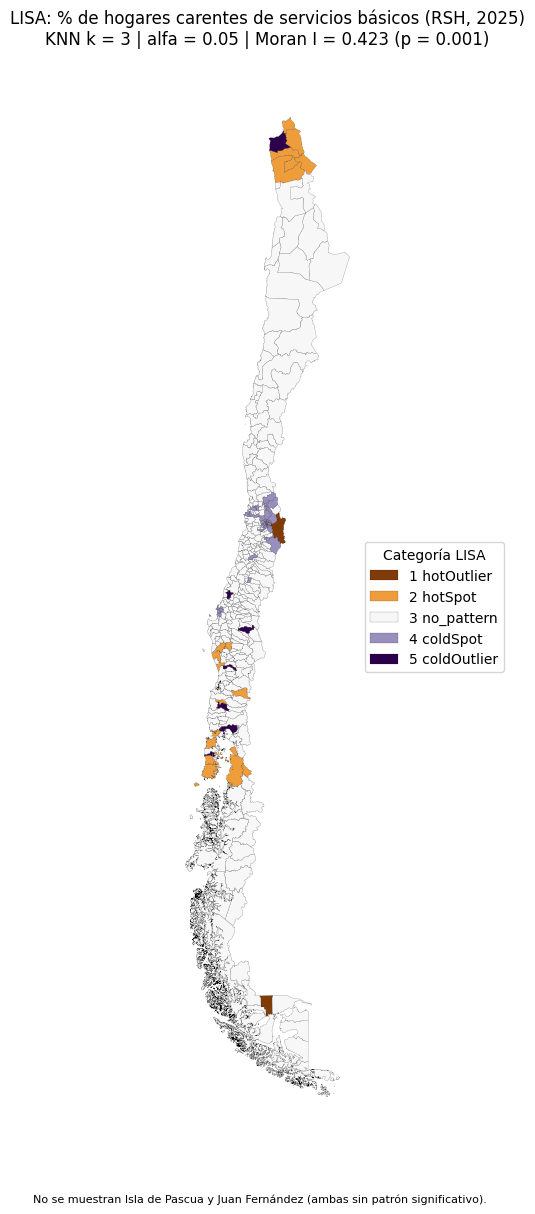

In [ ]:
from matplotlib.colors import ListedColormap

orden = ['1 hotOutlier', '2 hotSpot', '3 no_pattern', '4 coldSpot', '5 coldOutlier']
paleta = ListedColormap([plt.get_cmap('PuOr', 5)(i) for i in range(5)])
chile_lisa["LISA"] = pd.Categorical(chile_lisa["LISA"], categories=orden, ordered=True)

# Islas oceánicas: se muestran aparte porque estiran el mapa miles de kilómetros
islas = ["IsladePascua", "JuanFernández"]
continental = chile_lisa[~chile_lisa["Comuna"].isin(islas)]
print(chile_lisa[chile_lisa["Comuna"].isin(islas)][["Comuna", "LISA"]])   # categoría de las islas

fig, ax = plt.subplots(figsize=(6, 14))
continental.plot(column="LISA", categorical=True, cmap=paleta, linewidth=0.1, edgecolor="k",
                 legend=True, legend_kwds={"loc": "center left", "bbox_to_anchor": (1.0, 0.5),
                                           "title": "Categoría LISA"}, ax=ax)
ax.set_title("LISA: % de hogares carentes de servicios básicos (RSH, 2025)\n"
             f"KNN k = 3 | alfa = 0.05 | Moran I = {moran.I:.3f} (p = {moran.p_sim:.3f})")
fig.text(0.5, 0.07, "No se muestran Isla de Pascua y Juan Fernández (ambas sin patrón significativo).",
         ha="center", fontsize=8)
ax.set_axis_off()
plt.savefig("mapa_LISA_Chile.png", dpi=200, bbox_inches="tight")
plt.show()

# 13. Comunas por categoría
Listo las comunas de cada categoría con su valor, el promedio de sus tres vecinos (rezago) y su pseudo p-valor, para interpretar los spots y los outliers.

In [ ]:
for c in ['2 hotSpot', '4 coldSpot', '1 hotOutlier', '5 coldOutlier']:
    print("\n==", c)
    display(chile_lisa[chile_lisa["LISA"] == c][["NAME_1", "Comuna", var, "Rezago", "p_sim"]]
            .sort_values(["NAME_1", var]).round(3))


== 2 hotSpot


,NAME_1,Comuna,Hogares_Carentes_de_Servicios_Basicos,Rezago,p_sim
39,Araucanía,Traiguén,23.262,45.289,0.017
26,Araucanía,TeodoroSchmidt,34.098,41.673,0.037
9,Araucanía,Carahue,35.230,45.597,0.015
36,Araucanía,Lumaco,42.131,43.675,0.024
44,AricayParinacota,Putre,58.824,60.937,0.002
42,AricayParinacota,Camarones,74.569,44.828,0.015
43,AricayParinacota,GeneralLagos,96.959,48.225,0.004
148,LosLagos,CuracodeVélez,27.051,40.665,0.031
172,LosLagos,Futaleufú,27.094,42.396,0.021
161,LosLagos,Maullín,30.437,39.364,0.035



== 4 coldSpot


,NAME_1,Comuna,Hogares_Carentes_de_Servicios_Basicos,Rezago,p_sim
85,Bío-Bío,Chiguayante,3.492,7.388,0.002
89,Bío-Bío,Hualpén,3.682,6.261,0.001
93,Bío-Bío,SanPedrodelaPaz,4.960,4.856,0.001
92,Bío-Bío,Penco,6.300,11.088,0.048
95,Bío-Bío,Talcahuano,6.431,4.981,0.001
...,...,...,...,...,...
343,Valparaíso,Valparaíso,11.877,9.922,0.027
310,Valparaíso,Rinconada,12.540,10.356,0.036
308,Valparaíso,CalleLarga,13.417,9.407,0.024
335,Valparaíso,Putaendo,16.162,8.335,0.013



== 1 hotOutlier


,NAME_1,Comuna,Hogares_Carentes_de_Servicios_Basicos,Rezago,p_sim
188,MagallanesyAntárticaChilena,LagunaBlanca,28.276,10.135,0.028
253,SantiagoMetropolitan,SanJosédeMaipo,32.011,8.066,0.011



== 5 coldOutlier


,NAME_1,Comuna,Hogares_Carentes_de_Servicios_Basicos,Rezago,p_sim
22,Araucanía,Pitrufquén,21.800,41.395,0.038
41,AricayParinacota,Arica,11.282,76.784,0.001
82,Bío-Bío,SantaBárbara,22.256,38.355,0.043
164,LosLagos,Osorno,10.108,46.549,0.009
162,LosLagos,PuertoMontt,12.641,41.329,0.030
146,LosLagos,Castro,16.647,37.904,0.047
240,Ñuble,Quirihue,22.117,42.878,0.019


In [ ]:
# Resumen de los resultados LISA que sustentan la interpretación
resumen = chile_lisa["LISA"].value_counts().reindex(orden)
resumen.loc["Total significativas"] = resumen.iloc[[0, 1, 3, 4]].sum()
resumen.loc["Total comunas"] = len(chile_lisa)
resumen

,count
LISA,
1 hotOutlier,2
2 hotSpot,21
3 no_pattern,252
4 coldSpot,63
5 coldOutlier,7
Total significativas,93
Total comunas,345


# 14. Interpretación de los spots y los outliers

El Moran Global fue de 0.423 (pseudo p-valor = 0.001): hay autocorrelación espacial positiva y moderada, es decir, las comunas con porcentajes parecidos de hogares carentes de servicios básicos tienden a estar cerca. Como la variable mide carencia, un valor alto es una situación desfavorable.

**Spots.** Los 21 hotSpots (alta carencia rodeada de alta carencia) se concentran en el extremo norte (Arica y Parinacota y Tarapacá), en Araucanía (Traiguén, Teodoro Schmidt, Carahue y Lumaco) y, sobre todo, en Los Lagos, que reúne diez. Los 63 coldSpots (baja carencia rodeada de baja carencia) se concentran en la zona central: 39 están en la Región Metropolitana y el resto en Valparaíso, Bío-Bío, O'Higgins y Maule. Es decir, la alta carencia se agrupa en los extremos norte y sur, y la baja carencia en el centro.

**Outliers.** Los 7 coldOutliers son comunas con baja carencia rodeadas de comunas con carencia alta; destacan Arica, Osorno, Puerto Montt y Castro, que son ciudades importantes de su región. Los 2 hotOutliers, Laguna Blanca y San José de Maipo, tienen carencia alta rodeada de comunas con carencia baja. Los datos muestran dónde ocurren estos patrones, pero no permiten explicar por qué.

# 15. Limitaciones
Se usó un solo vecindario (KNN, k = 3), y con KNN cada comuna tiene tres vecinos aunque estén lejos (por ejemplo, Isla de Pascua). El nivel 0.05 se aplicó sin corrección por comparaciones múltiples, y los p-valores cercanos a 0.05 pueden cambiar entre ejecuciones.